In [21]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import PROCESSED, ROOT
from src.indicators import atr
import itertools
from src.strategies import señales_ruptura_ny,señales_reversion
from src.backtest import simular_trade, backtest,placebo_direccion

df = pd.read_parquet(PROCESSED)
df["atr"] = atr(df, 14)

In [23]:
o, h, l, c = (df[col].values for col in ["open", "high", "low", "close"])
print(simular_trade(o, h, l, c, i=1000, direccion=1, sl_dist=2.0, tp_dist=3.0, max_velas=24, coste=0.25))
print(simular_trade(o, h, l, c, i=1000, direccion=-1, sl_dist=2.0, tp_dist=3.0, max_velas=24, coste=0.25))

{'entrada_idx': 1000, 'direccion': 1, 'entrada': np.float64(1567.03), 'salida': np.float64(1565.03), 'motivo': 'SL', 'velas': 1, 'pnl': np.float64(-2.25), 'R': np.float64(-1.125)}
{'entrada_idx': 1000, 'direccion': -1, 'entrada': np.float64(1567.03), 'salida': np.float64(1569.03), 'motivo': 'SL', 'velas': 16, 'pnl': np.float64(-2.25), 'R': np.float64(-1.125)}


In [24]:
df.iloc[1000:1024][["open", "high", "low", "close"]]

,open,high,low,close
datetime,,,,
2020-01-07 15:20:00,1567.03,1567.54,1564.69,1565.21
2020-01-07 15:25:00,1565.23,1566.52,1565.19,1566.35
2020-01-07 15:30:00,1566.35,1566.81,1565.49,1566.49
2020-01-07 15:35:00,1566.40,1567.51,1566.38,1567.29
2020-01-07 15:40:00,1567.29,1567.44,1566.47,1567.37
2020-01-07 15:45:00,1567.37,1567.77,1566.87,1567.36
2020-01-07 15:50:00,1567.38,1568.27,1567.26,1567.39
2020-01-07 15:55:00,1567.39,1568.31,1567.25,1568.18
2020-01-07 16:00:00,1568.18,1568.57,1567.16,1567.50


In [25]:
rng = np.random.default_rng(0)
señales_pocas = pd.Series(rng.choice([0, 1, -1], size=len(df), p=[0.998, 0.001, 0.001]), index=df.index)
trades_pocas = backtest(df, señales_pocas, sl_mult=1.5, tp_mult=2.0, max_velas=24, coste=0.25)
print(len(trades_pocas), trades_pocas["R"].mean())
trades_pocas.groupby(df.index[trades_pocas["entrada_idx"]].year)["R"].agg(["mean", "count"])

993 -0.1471766384599079


,mean,count
datetime,,
2020,-0.159395,142
2021,-0.283060,146
2022,-0.277293,147
2023,-0.128198,157
2024,-0.273924,127
2025,0.061928,154
2026,0.032960,120


In [26]:
rng = np.random.default_rng(0)
señales_ctrl = pd.Series(rng.choice([0, 1, -1], size=len(df), p=[0.98, 0.01, 0.01]), index=df.index)
trades = backtest(df, señales_ctrl, sl_mult=1.5, tp_mult=2.0, max_velas=24, coste=0.25)
print(len(trades), trades["R"].mean())
trades.groupby(df.index[trades["entrada_idx"]].year)["R"].agg(["mean", "count"])


8416 -0.13240933402634328


,mean,count
datetime,,
2020,-0.081619,1242
2021,-0.179887,1263
2022,-0.165457,1196
2023,-0.179012,1259
2024,-0.091607,1200
2025,-0.113135,1289
2026,-0.110409,967


In [27]:
control = trades.copy()
control.to_parquet(ROOT / "reports" / "control_aleatorio.parquet")

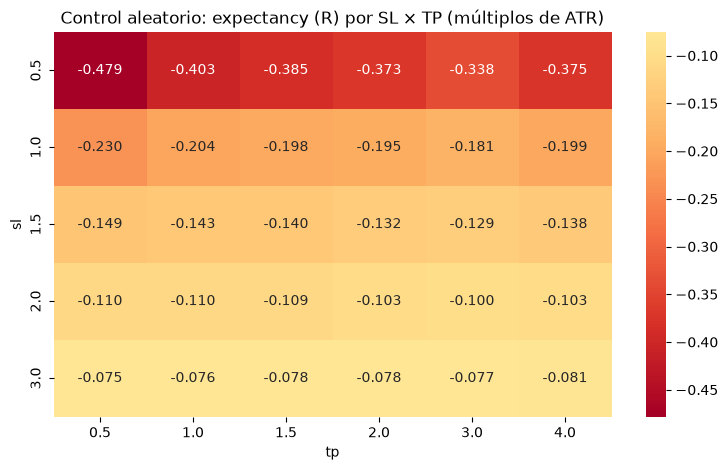

In [28]:
sl_list = [0.5, 1.0, 1.5, 2.0, 3.0]
tp_list = [0.5, 1.0, 1.5, 2.0, 3.0, 4.0]

filas = []
for sl_m, tp_m in itertools.product(sl_list, tp_list):
    t = backtest(df, señales_ctrl, sl_mult=sl_m, tp_mult=tp_m, max_velas=24, coste=0.25)
    filas.append({"sl": sl_m, "tp": tp_m,
                  "expR": t["R"].mean(),
                  "winrate": (t["R"] > 0).mean(),
                  "n": len(t)})

grid_ctrl = pd.DataFrame(filas)
tabla = grid_ctrl.pivot(index="sl", columns="tp", values="expR")

plt.figure(figsize=(9, 5))
sns.heatmap(tabla, annot=True, fmt=".3f", cmap="RdYlGn", center=0)
plt.title("Control aleatorio: expectancy (R) por SL × TP (múltiplos de ATR)")
plt.show()

In [29]:
grid_ctrl.query("sl == 2.0 and tp == 0.5")

,sl,tp,expR,winrate,n
18,2.0,0.5,-0.109737,0.758583,9233


In [30]:
señ_B = señales_ruptura_ny(df)
print(f"Semañales totles: {(señ_B != 0).sum()}\nCompras: {(señ_B == 1).sum()}\nVetnas: {(señ_B == -1).sum()}")

Semañales totles: 1588
Compras: 846
Vetnas: 742


In [31]:
trades_B = backtest(df, señ_B, sl_mult=1.5, tp_mult=2.0, max_velas=24, coste=0.25)

# Resumen global
r = trades_B["R"]
t_stat = r.mean() / r.std() * np.sqrt(len(r))          # ¿es distinguible de 0?
print(f"Trades: {len(r)}  |  expR: {r.mean():.3f}  |  t-stat: {t_stat:.2f}")
print(f"Control (misma SL/TP): {control['R'].mean():.3f}")

# Año a año, frente al control
años_B = df.index[trades_B["entrada_idx"]].year
años_C = df.index[control["entrada_idx"]].year
comp = pd.DataFrame({"B_expR": trades_B.groupby(años_B)["R"].mean(),
                     "B_n": trades_B.groupby(años_B)["R"].count(),
                     "control_expR": control.groupby(años_C)["R"].mean()})
comp["ventaja"] = comp["B_expR"] - comp["control_expR"]
comp.round(3)

Trades: 1588  |  expR: -0.078  |  t-stat: -2.69
Control (misma SL/TP): -0.132


,B_expR,B_n,control_expR,ventaja
datetime,,,,
2020,-0.112,230,-0.082,-0.030
2021,-0.142,225,-0.180,0.038
2022,-0.135,233,-0.165,0.031
2023,-0.081,239,-0.179,0.098
2024,-0.037,245,-0.092,0.054
2025,0.008,243,-0.113,0.122
2026,-0.046,173,-0.110,0.064


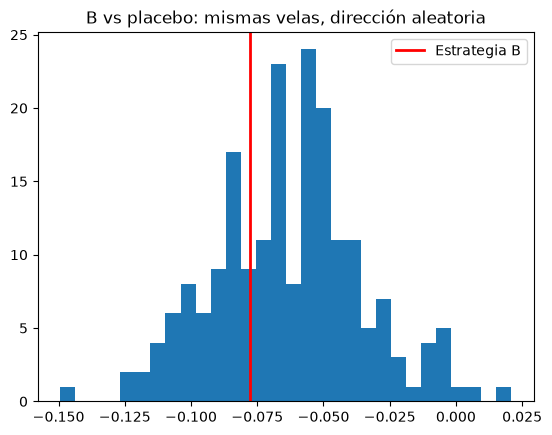

Placebo medio: -0.063  |  B: -0.078  |  p-valor: 0.695


In [32]:
mask_B = señ_B != 0
resultados = []
for seed in range(200):
    rng = np.random.default_rng(seed)
    señ_rand = señ_B.copy()
    señ_rand[mask_B] = rng.choice([1, -1], size=mask_B.sum())     # mismas velas, dirección al azar
    t = backtest(df, señ_rand, sl_mult=1.5, tp_mult=2.0, max_velas=24, coste=0.25)
    resultados.append(t["R"].mean())

placebo = np.array(resultados)
p_valor = (placebo >= trades_B["R"].mean()).mean()                  # % de placebos que igualan o superan a B

plt.hist(placebo, bins=30)
plt.axvline(trades_B["R"].mean(), color="red", lw=2, label="Estrategia B")
plt.legend(); plt.title("B vs placebo: mismas velas, dirección aleatoria"); plt.show()
print(f"Placebo medio: {placebo.mean():.3f}  |  B: {trades_B['R'].mean():.3f}  |  p-valor: {p_valor:.3f}")

Señales: 2950 | compras: 1416 | ventas: 1534
Trades: 2950 | expR: -0.109 | t-stat: -7.52
           mean  count
datetime              
2020     -0.080    422
2021     -0.151    441
2022     -0.157    444
2023     -0.085    436
2024     -0.112    441
2025     -0.106    436
2026     -0.053    330


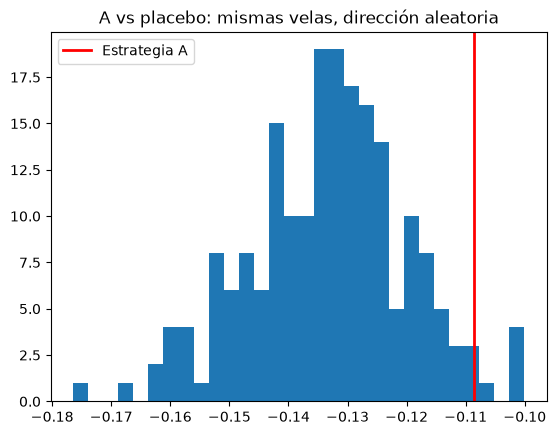

Placebo medio: -0.133 | A: -0.109 | p-valor: 0.030


In [36]:
señ_A = señales_reversion(df)
print("Señales:", (señ_A != 0).sum(), "| compras:", (señ_A == 1).sum(), "| ventas:", (señ_A == -1).sum())

params_A = dict(sl_mult=1.5, tp_mult=1.0, max_velas=12, coste=0.25)
trades_A = backtest(df, señ_A, **params_A)
rA = trades_A["R"]
print(f"Trades: {len(rA)} | expR: {rA.mean():.3f} | t-stat: {rA.mean()/rA.std()*np.sqrt(len(rA)):.2f}")

# Año a año
print(trades_A.groupby(df.index[trades_A["entrada_idx"]].year)["R"].agg(["mean", "count"]).round(3))

# Placebo: mismas velas, dirección aleatoria
plac_A = placebo_direccion(df, señ_A, **params_A)
p_A = (plac_A >= rA.mean()).mean()
plt.hist(plac_A, bins=30)
plt.axvline(rA.mean(), color="red", lw=2, label="Estrategia A")
plt.legend(); plt.title("A vs placebo: mismas velas, dirección aleatoria"); plt.show()
print(f"Placebo medio: {plac_A.mean():.3f} | A: {rA.mean():.3f} | p-valor: {p_A:.3f}")